C:\Users\admin\AppData\Local\Temp\ipykernel_16476\3234755489.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  db['Date']= pd.to_datetime(db['Date'])


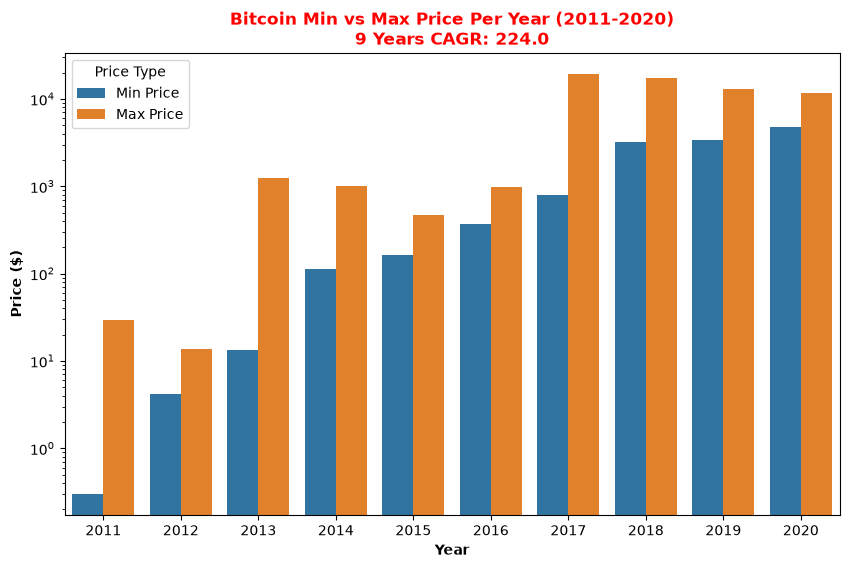

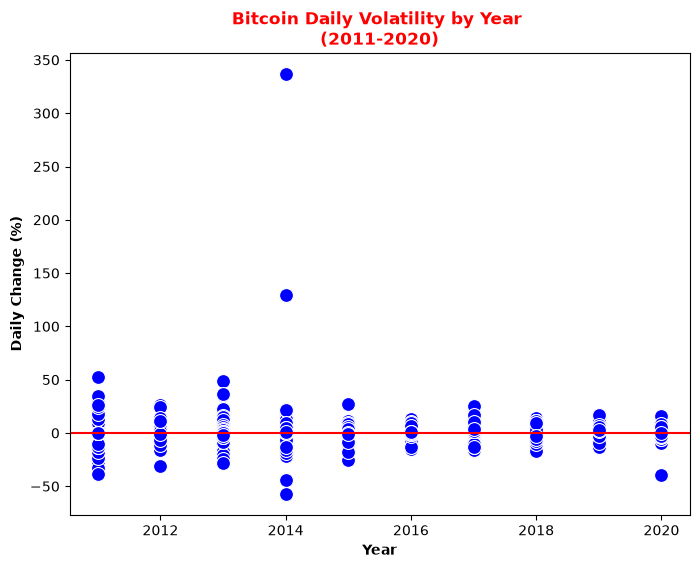

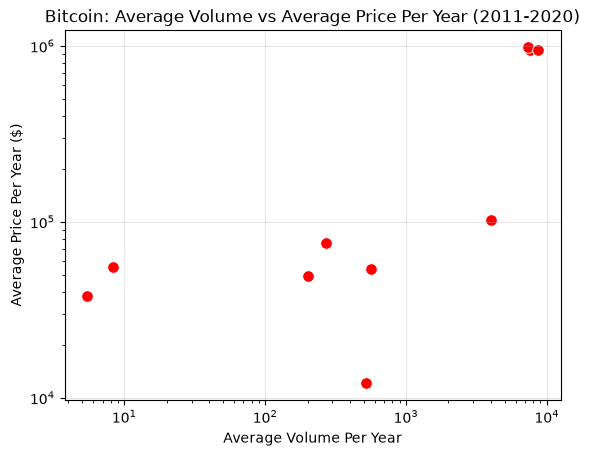

0.95


Year
2011       5.446518
2012       8.291803
2013     200.149041
2014     522.891233
2015     272.024110
2016     566.997814
2017    3981.072329
2018    7552.158356
2019    7371.821918
2020    8650.557674
Name: Price, dtype: float64

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv('Bitcoin Historical Data.csv')
db= data.copy()
db['Date']= pd.to_datetime(db['Date'])
db.head()
db.duplicated().any()
db.isnull().any()
db['Year']=db['Date'].dt.year
db['Month']=db['Date'].dt.month_name()
db.head().sort_values(by= 'Date')
db[['Price', 'Open', 'High', 'Low']]=db[['Price', 'Open', 'High', 'Low']] .apply(lambda x: x.astype(str).str.replace(',', '').astype(float))
db['Change %'] = db['Change %'].astype(str).str.replace('%', '').astype(float)
db['Change %']
db[db['Vol.'] == '-']
db['Vol.'].value_counts().head(10) #checking for bad data
db['Change %'].value_counts().head(10)
db=db[db['Vol.']!= '-']
def clean_volume(value): #function to convert Vol. to Float
    value = str(value).strip()
    if value.endswith('K'):
        return float(value[:-1]) * 1000
    if value.endswith('M'):
        return float(value[:-1]) * 1000000
    return float(value)

db['Vol.'] = db['Vol.'].apply(clean_volume)
db=db[db['Year']!= 2010]


#finding the CAGR over the course of 9 years 
end_price = db[db['Year'] == 2020]['Price'].max()
start_price = db[db['Year'] == 2011]['Price'].min()

cag = (end_price / start_price) ** (1 / 9) - 1
cagr=round(cag * 100,2)

min_price_year=db.groupby('Year',as_index= False)['Price'].min()
max_price_year=db.groupby('Year',as_index= False)['Price'].max()
# Rename 'Price'
min_price_year = min_price_year.rename(columns={'Price': 'Min Price'})
max_price_year = max_price_year.rename(columns={'Price': 'Max Price'})

# Join them using Unique Id Year
yearly_range = pd.merge(min_price_year, max_price_year, on='Year')

# Group Chart data
final_data = yearly_range.melt(id_vars='Year', value_vars=['Min Price', 'Max Price'],
 var_name='Price Type', value_name='Price')


plt.figure(figsize=(10,6))
sns.barplot(data=final_data, x='Year', y='Price', hue='Price Type')
plt.title(f'Bitcoin Min vs Max Price Per Year (2011-2020)\n9 Years CAGR: {cagr}', color= 'red',fontweight= 'bold')
plt.ylabel('Price ($)',fontweight= 'bold')
plt.xlabel('Year',fontweight= 'bold')
plt.yscale('log')  # to avoid chart being squashed because 2011 is $0.30 and 2017 is $19,345
plt.show()
min_price_year[min_price_year['Year']== 2020]

# Plotting the volatitily of daily rate changes 
# No groupby, no mean - just plot every day, grouped by Year on the X-axis
plt.figure(figsize=(8,6))
sns.scatterplot(data=db, x='Year', y='Change %',s=100,marker='o',color='blue')
plt.axhline(0, color='red')
plt.title('Bitcoin Daily Volatility by Year \n(2011-2020)', color= 'red',fontweight= 'bold')
plt.xlabel('Year',fontweight= 'bold')
plt.ylabel('Daily Change (%)',fontweight= 'bold')
plt.show()

# Volume Vs Price , comparing how trading activity affect the price
price_avg= db.groupby('Year')['Price'].mean()
vol_avg=db.groupby('Year')['Vol.'].mean() 
sns.scatterplot (x=price_avg.values,y=vol_avg.values, s= 70, color='red')
plt.xlabel('Average Volume Per Year')
plt.ylabel('Average Price Per Year ($)')
plt.title('Bitcoin: Average Volume vs Average Price Per Year (2011-2020)')
plt.xscale('log')
plt.yscale('log')
plt.grid(alpha=0.3)
plt.show()
#correlation 
corr = round(vol_avg.corr(price_avg),2)
print(corr) 
